# Preparing

Устанавливаем и \ или запускаем библиотеки с функциями и всякие полезные фигни. Биоблиотеки нужно установить один раз. Запускать их нужно каждый раз перед тем, как запускать код.

In [1]:
! pip install PyQt5

In [2]:
! pip install scikit-learn

In [3]:
import mne #eeg analysis
import numpy as np # dataframes and staff
import matplotlib.pyplot as plt # plots
import matplotlib # plots
import PyQt5 # how plots open in you PC
from pathlib import Path # path to files
from mne.channels import find_ch_adjacency # connection btw electrodes
from functools import partial # statistics
import scipy.stats #statistics
import pickle # way to save data
import seaborn as sns # data and stats
from scipy import stats # stats
import statistics # stats

#the following magic line will make all of your figures to be of the chosen size (in inches)
%matplotlib qt5

# Load the file

Чтоб открыть файл, нужно указать к нему путь. Путь:

In [4]:
path_to_project = Path('D:/Studies/fake/exp_data/eeg_pretest/')

Потом нужно открыть файл(-ы) в этом пути.

In [5]:
sbj_id = '047' # participant's id. It's easier to load the file having this variable

In [7]:
raw = mne.io.read_raw_brainvision(path_to_project / f'{sbj_id}.vhdr', eog=['HEOG', 'VEOG'], misc = ['BIP1'], preload = True)

Extracting parameters from D:\Studies\fake\exp_data\eeg_pretest\047.vhdr...
Setting channel info structure...
Reading 0 ... 848624  =      0.000 ...  1697.248 secs...


Если в ЭЭГ есть глазные электроды, указывай это в параметре eog. misc не меняй, хз, что это, но надо. Preload позволяет обращаться к файлу со сложными задачами, без него только простые операции.

In [8]:
raw.info

Measurement date,"March 29, 2024 13:54:56 GMT"
Experimenter,Unknown
Participant,Unknown
Digitized points,Not available
Good channels,"60 EEG, 2 EOG"
Bad channels,None
EOG channels,"HEOG, VEOG"
ECG channels,Not available
Sampling frequency,500.00 Hz
Highpass,0.00 Hz
Lowpass,250.00 Hz


# Montage

Код не знает, как на голове расположены электроды. Их названия ему ничего не говорят. Надо до него это донести с мопощью подключения монтажа. Грубо говоря -- это карта расположения электродов в заивисимости от названия.

In [9]:
montage = mne.channels.make_standard_montage("standard_1020")

In [10]:
raw.rename_channels({'FP2':'Fp2'})

Measurement date,"March 29, 2024 13:54:56 GMT"
Experimenter,Unknown
Participant,Unknown
Digitized points,Not available
Good channels,"60 EEG, 2 EOG"
Bad channels,None
EOG channels,"HEOG, VEOG"
ECG channels,Not available
Sampling frequency,500.00 Hz
Highpass,0.00 Hz
Lowpass,250.00 Hz


In [11]:
raw.set_montage(montage)

Measurement date,"March 29, 2024 13:54:56 GMT"
Experimenter,Unknown
Participant,Unknown
Digitized points,63 points
Good channels,"60 EEG, 2 EOG"
Bad channels,None
EOG channels,"HEOG, VEOG"
ECG channels,Not available
Sampling frequency,500.00 Hz
Highpass,0.00 Hz
Lowpass,250.00 Hz


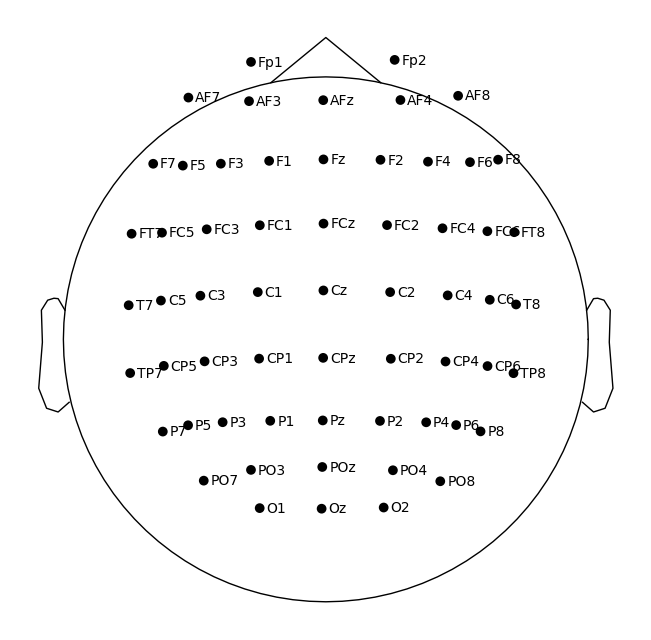

In [12]:
raw.plot_sensors(show_names = True) #What if we would like to see the names

# Filtering

In [13]:
raw.notch_filter(50)
raw.filter(1,45)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband edge: 50.62 Hz
- Upper transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 50.88 Hz)
- Filter length: 3301 samples (6.602 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.1s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.2s remaining:    0.0s


Filtering raw data in 1 contiguous segment


[Parallel(n_jobs=1)]: Done  60 out of  60 | elapsed:    3.7s finished


Setting up band-pass filter from 1 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 1651 samples (3.302 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done  60 out of  60 | elapsed:    1.8s finished


Measurement date,"March 29, 2024 13:54:56 GMT"
Experimenter,Unknown
Participant,Unknown
Digitized points,63 points
Good channels,"60 EEG, 2 EOG"
Bad channels,None
EOG channels,"HEOG, VEOG"
ECG channels,Not available
Sampling frequency,500.00 Hz
Highpass,1.00 Hz
Lowpass,45.00 Hz


In [15]:
raw.plot(duration = 100)

Channels marked as bad:
none


# ICA

Individual Component Analysis "объясняет" данные записи, деля их на компоненты. Например, фронтальный компонент (глаза), затылочный, и тд.
Это нужно для извлечения морганий.

In [16]:
ica = mne.preprocessing.ICA(n_components = 0.99)

In [17]:
ica.fit(raw, reject_by_annotation=True)

Fitting ICA to data using 60 channels (please be patient, this may take a while)
Selecting by explained variance: 10 components
Fitting ICA took 29.2s.


Method,fastica
Fit parameters,algorithm=parallelfun=logcoshfun_args=Nonemax_iter=1000
Fit,34 iterations on raw data (848625 samples)
ICA components,10
Available PCA components,60
Channel types,eeg
ICA components marked for exclusion,—


In [18]:
ica.plot_sources(raw)

Creating RawArray with float64 data, n_channels=12, n_times=848625
    Range : 0 ... 848624 =      0.000 ...  1697.248 secs
Ready.


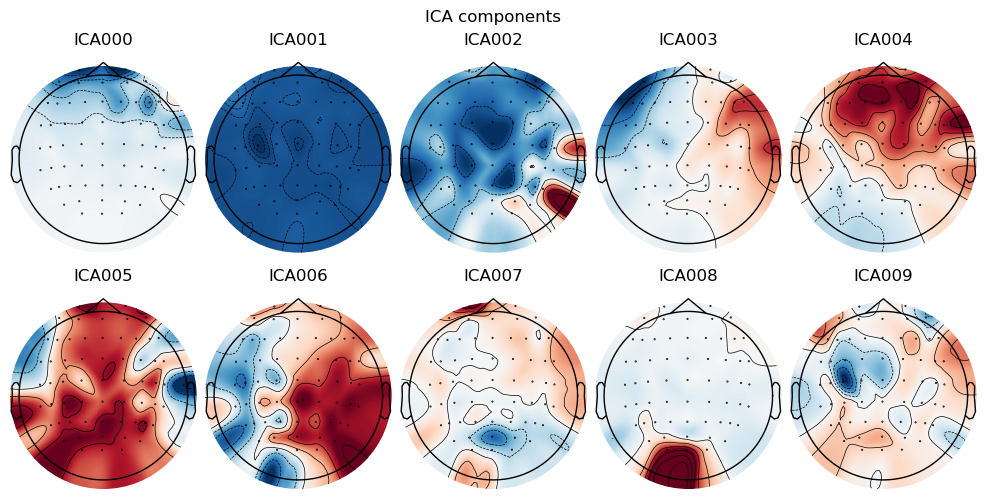

In [19]:
ica.plot_components()

In [20]:
ica.find_bads_eog(inst = raw, ch_name = ['HEOG', 'VEOG'], measure = 'correlation', threshold = 0.5)

Using EOG channels: HEOG, VEOG
... filtering ICA sources
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 5000 samples (10.000 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.1s remaining:    0.0s


... filtering target
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 5000 samples (10.000 s)



[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:    0.3s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished


... filtering ICA sources
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 5000 samples (10.000 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.1s remaining:    0.0s


... filtering target
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 5000 samples (10.000 s)



[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:    0.3s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished


([0, 3],
 [array([-0.78323782, -0.14738958, -0.03288316, -0.59776735,  0.01819553,
         -0.05084465, -0.05814548,  0.04034394,  0.0015436 ,  0.04215113]),
  array([ 0.82821155, -0.11386542,  0.00137796,  0.11739881, -0.01218378,
         -0.19342767,  0.02392819, -0.00232075,  0.03261205, -0.01249831])])

Using EOG channels: HEOG, VEOG
... filtering ICA sources
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 5000 samples (10.000 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.1s remaining:    0.0s


... filtering target
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 5000 samples (10.000 s)



[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:    0.3s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished


... filtering ICA sources
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 5000 samples (10.000 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.1s remaining:    0.0s


... filtering target
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 5000 samples (10.000 s)



[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:    0.4s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished


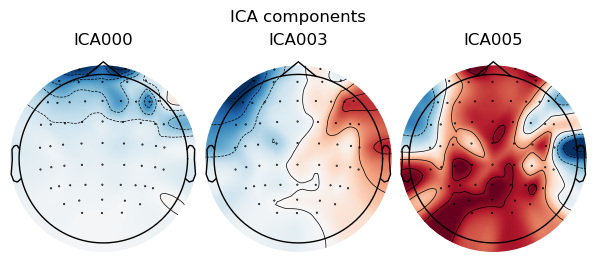

In [21]:
#find which ICs match the EOG pattern
ica.exclude = []
eog_indices, eog_scores = ica.find_bads_eog(raw, threshold = 0.75)
#ica.exclude = eog_indices
ica.plot_components(eog_indices)

In [22]:
ica.exclude = [0, 3]
ica.apply(raw)

Applying ICA to Raw instance
    Transforming to ICA space (10 components)
    Zeroing out 2 ICA components
    Projecting back using 60 PCA components


Measurement date,"March 29, 2024 13:54:56 GMT"
Experimenter,Unknown
Participant,Unknown
Digitized points,63 points
Good channels,"60 EEG, 2 EOG"
Bad channels,None
EOG channels,"HEOG, VEOG"
ECG channels,Not available
Sampling frequency,500.00 Hz
Highpass,1.00 Hz
Lowpass,45.00 Hz


In [23]:
raw.plot()

Channels marked as bad:
none


# Epoch

Эпохи -- это вычленение из записи только секунды после метки.

In [24]:
events, ids = mne.events_from_annotations(raw)

Used Annotations descriptions: ['NOISE', 'New Segment/', 'Stimulus/S  1', 'Stimulus/S  2', 'Stimulus/S  3', 'Stimulus/S  4', 'Stimulus/S  5', 'Stimulus/S  6']


In [25]:
ids

{'NOISE': 10001,
 'New Segment/': 99999,
 'Stimulus/S  1': 1,
 'Stimulus/S  2': 2,
 'Stimulus/S  3': 3,
 'Stimulus/S  4': 4,
 'Stimulus/S  5': 5,
 'Stimulus/S  6': 6}

In [26]:
dis_ids = {'t_avt': 3, 't_non': 5, 'f_avt': 4, 'f_non': 6}

In [27]:
dis_events = mne.pick_events(events, include = [3, 4, 5, 6])

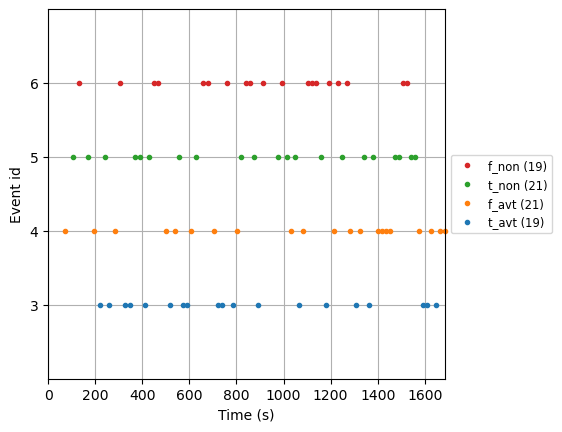

In [28]:
mne.viz.plot_events(dis_events, event_id = dis_ids, sfreq = raw.info['sfreq'])

tmin -- престимульный интервал, часто 0.5 - 0.1. tmax -- постстимульный интервал -- чаще 1. baseline первое число совпадает с престимулом, второе число 0.

In [29]:
epochs_dis = mne.Epochs(raw, dis_events, dis_ids, tmin = -0.5, tmax = 1, baseline = (-0.5, 0), reject_by_annotation=True)

Not setting metadata
80 matching events found
Applying baseline correction (mode: mean)
0 projection items activated


In [30]:
epochs_dis.plot()

Using data from preloaded Raw for 80 events and 751 original time points ...
0 bad epochs dropped
Using data from preloaded Raw for 20 events and 751 original time points ...
Using data from preloaded Raw for 8 events and 751 original time points ...


# Evokeds

ERP из эпох.

In [33]:
evoked_dis = epochs_dis.average()
evoked_dis

Condition,0.23 × t_avt + 0.27 × t_non + 0.26 × f_avt + 0.24 × f_non
Data kind,average
Timepoints,751 samples
Channels,60 channels
Number of averaged epochs,78
Time range (secs),-0.5 – 1.0
Baseline (secs),-0.500 – 0.000 s


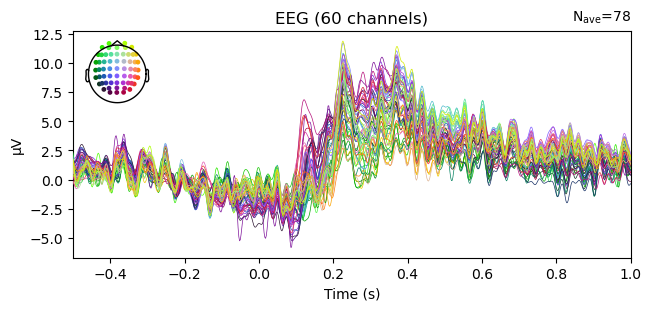

In [34]:
evoked_dis.plot()

In [35]:
my_evokeds = {}
for condition in epochs_dis.event_id:
    my_evokeds[condition] =  epochs_dis[condition].average()
    
my_evokeds

{'t_avt': <Evoked | 't_avt' (average, N=18), -0.5 – 1 s, baseline -0.5 – 0 s, 60 ch, ~442 kB>,
 't_non': <Evoked | 't_non' (average, N=21), -0.5 – 1 s, baseline -0.5 – 0 s, 60 ch, ~442 kB>,
 'f_avt': <Evoked | 'f_avt' (average, N=20), -0.5 – 1 s, baseline -0.5 – 0 s, 60 ch, ~442 kB>,
 'f_non': <Evoked | 'f_non' (average, N=19), -0.5 – 1 s, baseline -0.5 – 0 s, 60 ch, ~442 kB>}

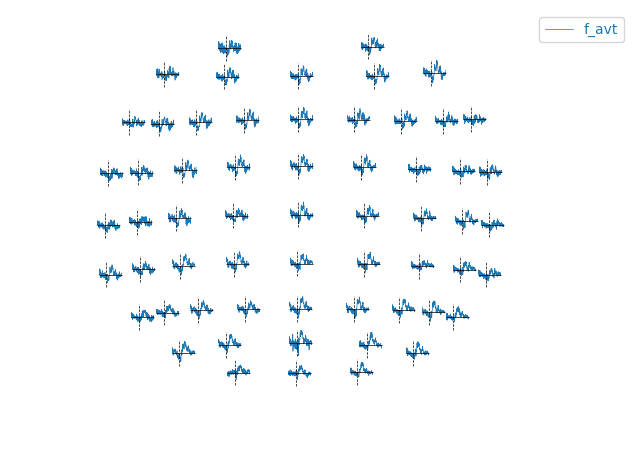

In [37]:
my_evokeds['f_avt'].plot_topo() # условие в квадратной скобке можно менять

In [39]:
mne.viz.plot_compare_evokeds(my_evokeds)

[<Figure size 800x600 with 1 Axes>]

In [40]:
mne.viz.plot_compare_evokeds(
    my_evokeds,
    colors=dict(t_avt=0, f_avt=1, t_non=0, f_non=1),
    linestyles=dict(t_avt='solid', f_avt='solid', t_non='dashed', f_non='dashed'),
    axes="topo",
    vlines = [0.0, 0.1, 0.3]
)

[<Figure size 1800x1011 with 61 Axes>]